# 현실의 데이터 12: 여행 예약: 취소와 가격

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/12_hotel_booking.ipynb)

**분야**: 플랫폼 · 서비스 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 실시간 가격책정 · 여행일정 개인화 · 수요-공급 매칭

> 포르투갈 호텔 예약 12만 건. 이 예약은 취소될까? 1박에 얼마가 맞을까?

**데이터**: Hotel Booking Demand (약 17MB). Antonio, Almeida & Nunes (2019), Data in Brief. 포르투갈 리조트 호텔 · 도시 호텔 2곳의 2015~2017 예약 119,390건 (TidyTuesday 2020-02-11).

산업 현장의 문제와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 예약 한 건 |
| ② 입력 X | 예약 시점에 아는 것: 며칠 전 예약 · 인원 · 박 수 · 고객 유형 … |
| ③ 출력 y | 취소할까 (분류) / 1박 가격 adr (회귀) |
| ④ 평가지표 | 정밀도 · 재현율 / MAE (유로) |
| ⑤ 기준선 | 아무도 취소 안 함 / 같은 달 평균 가격 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Antonio, Almeida & Nunes (2019) Hotel booking demand datasets, Data in Brief](https://doi.org/10.1016/j.dib.2018.11.126)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

In [2]:
URL = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv"
df = pd.read_csv(download(URL, "data/hotels.csv"))
print(df.shape)
df.head(3).T.head(20)

(119390, 32)


,0,1,2
hotel,Resort Hotel,Resort Hotel,Resort Hotel
is_canceled,0,0,0
lead_time,342,737,7
arrival_date_year,2015,2015,2015
arrival_date_month,July,July,July
arrival_date_week_number,27,27,27
arrival_date_day_of_month,1,1,1
stays_in_weekend_nights,0,0,0
stays_in_week_nights,0,0,1
adults,2,2,1


## 열어 보기

취소율, 1박 가격 (`adr`, 유로) 의 분포, 달마다 가격.

cancellation rate: 37.0%
count    119390.0
mean        101.8
std          50.5
min          -6.4
25%          69.3
50%          94.6
75%         126.0
max        5400.0
Name: adr, dtype: float64


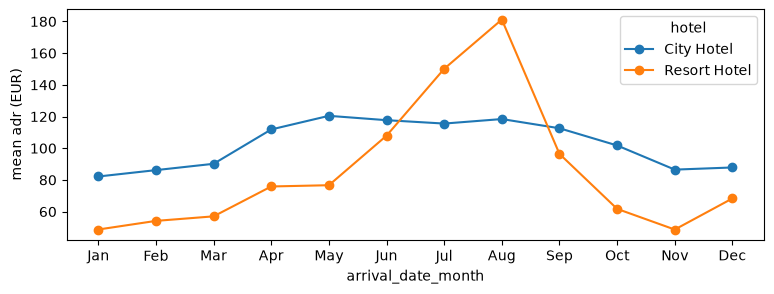

In [3]:
print(f"cancellation rate: {df['is_canceled'].mean():.1%}")
print(df["adr"].describe().round(1))
months = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
price = df[df["is_canceled"] == 0].groupby(["arrival_date_month", "hotel"])["adr"].mean().unstack().reindex(months)
price.plot(figsize=(9, 3), marker="o"); plt.ylabel("mean adr (EUR)"); plt.xticks(range(12), [m[:3] for m in months]); plt.show()

## 문제 1: 예약 → 취소할까 (분류)

**함정 하나**: `reservation_status` 열이 있다. 값이 `Canceled` 면 취소된 것이다. 이걸 입력에 넣으면?
예약하는 순간에는 알 수 없는 값 = **답이 새는 입력 (누수, leakage)**. 넣을 때와 뺄 때를 비교한다. 시험은 **시간 순서** 로 2017년 예약.

In [4]:
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor

def precision_recall(y_true, y_pred):
    tp = np.sum((y_pred == 1) & (y_true == 1)); fp = np.sum((y_pred == 1) & (y_true == 0)); fn = np.sum((y_pred == 0) & (y_true == 1))
    return (tp / (tp + fp) if tp + fp else 0.0), tp / (tp + fn)

known = ["hotel", "lead_time", "arrival_date_month", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children",
         "babies", "meal", "market_segment", "distribution_channel", "is_repeated_guest", "previous_cancellations",
         "booking_changes", "deposit_type", "customer_type", "total_of_special_requests", "required_car_parking_spaces"]
leaky = known + ["reservation_status"]
train, test = df[df["arrival_date_year"] < 2017], df[df["arrival_date_year"] == 2017]

def fit_cancel(cols, train, test):
    """Gradient boosting on the given columns; returns predictions for test"""
    enc = pd.get_dummies(pd.concat([train[cols], test[cols]]), dtype=float)
    m = HistGradientBoostingClassifier(random_state=0).fit(enc.iloc[:len(train)], train["is_canceled"])
    return m.predict(enc.iloc[len(train):])

y = test["is_canceled"].values
for name, pred in [("nobody cancels", np.zeros(len(y), dtype=int)), ("known at booking", fit_cancel(known, train, test)),
                   ("+ reservation_status", fit_cancel(leaky, train, test))]:
    p, r = precision_recall(y, pred)
    print(f"{name:22s} accuracy {np.mean(pred == y):.1%}  precision {p:.0%}  recall {r:.0%}")

nobody cancels         accuracy 61.3%  precision 0%  recall 0%
known at booking       accuracy 77.0%  precision 78%  recall 56%
+ reservation_status   accuracy 100.0%  precision 100%  recall 100%


## 문제 2: 같은 데이터, 예약 → 1박 가격 (회귀)

취소되지 않은 예약만. 기준선 = 학습 기간의 '같은 호텔 · 같은 달' 평균 가격.

In [5]:
ok_train, ok_test = train[train["is_canceled"] == 0], test[test["is_canceled"] == 0]
month_mean = ok_train.groupby(["hotel", "arrival_date_month"])["adr"].mean()
base = ok_test.set_index(["hotel", "arrival_date_month"]).index.map(month_mean).values
enc = pd.get_dummies(pd.concat([ok_train[known], ok_test[known]]), dtype=float)
reg = HistGradientBoostingRegressor(random_state=0).fit(enc.iloc[:len(ok_train)], ok_train["adr"])
pred = reg.predict(enc.iloc[len(ok_train):])
print(f"baseline (hotel x month mean): MAE {np.nanmean(np.abs(base - ok_test['adr'])):.1f} EUR")
print(f"gradient boosting            : MAE {np.mean(np.abs(pred - ok_test['adr'])):.1f} EUR")

baseline (hotel x month mean): MAE 30.4 EUR
gradient boosting            : MAE 22.6 EUR


**관찰**: 2017년 가격이 2015~2016년보다 올랐다면, 과거 평균은 미래 가격을 낮게 잡는다 (1주 3차시 항공 승객과 같은 이야기).

## 다른 문제로 바꿔 보기

- **실시간 가격책정**: '가격' 을 맞히는 것과 '얼마를 받아야 이익이 최대인가' 는 다른 문제다. 가격을 바꿨을 때 예약이 어떻게 변하는지는 이 데이터만으로 알 수 있을까?
- **수요-공급 매칭**: 한 행을 '예약' 이 아니라 '호텔 × 날짜' 로 바꾸면 '그날 방이 몇 개 찰까' 를 맞히는 문제가 된다.
- **여행일정 개인화**: 고객 한 명의 과거 예약이 여러 개 있어야 한다. 이 데이터에는 고객 번호가 없다.

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |